# Gotthard — single and double spectral spikes
FLASH gas beamtime, November 2026. Start with the long ethanol delay scan at 271.5 eV.

Use the **combined H5**, not the aggregates: the latter store moments/means rather than individual spectra. If the combined file was written with `--no-vls`, use the raw-run reader from `analysis/scripts/photon_energy.py` by setting `RAW_RUN` to the actual run number. No electron/ion arrays are loaded. Nothing is written to the combined H5.

The detector is taken from `static_xas_analysis.py` (`detect_double_peaks_pairscan`), with the actual parameters used in `xas_static_shot_resolved_E.ipynb` (the later pair-scan cell, not the earlier detector). The old test file tests one clean Gaussian and one double Gaussian. We retain the pair score, including the optional COM bonus, and expose two extra diagnostics.

Changes for this beamtime: dark-slot pedestal, common mode, bad-pixel interpolation (instead of zeroing inside a peak), noise estimated before clipping, a dark-derived signal threshold instead of the old 1000 ADU cut, explicit missing/weak/ambiguous categories, and a second, relaxed pair search. All thresholds are starting values. A spectral double peak is not evidence by itself for two pulses in time.

In [2]:
import os, sys
from pathlib import Path
from typing import Optional
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, savgol_filter
from scipy.ndimage import uniform_filter1d
from IPython.display import display

os.environ.setdefault('FLASH_ENV', 'remote')
REPO_ROOT = Path.home() / 'glycine26_gas_vls'
SCRIPTS = REPO_ROOT / 'analysis' / 'scripts'
if str(SCRIPTS) not in sys.path:
    sys.path.insert(0, str(SCRIPTS))

## 1. Config
All pixel ranges are half-open. Start with `TRAIN_STEP = 10` for a fast first look if needed; set it back to 1 for final counts. The first two bunch slots are excluded by default, as in the beamtime background convention; inspect the bunch plot and adjust if needed.

In [3]:
MEASUREMENT = 'Ethanol_short_delay_scan_3_271_5eV_2809292235'
COMBINED_DIR = Path(os.environ.get('FLASH_DATA_DIR', '/asap3/flash/gpfs/fl24/2026/data/11024642')) / 'processed' / 'combined'
INPUT_H5 = None                 # exact Path if automatic filename lookup is ambiguous
RAW_RUN = None                  # actual run number, only needed if vls is absent
VLS_OFFSET = 2                  # raw route only; combined VLS is already aligned
TRAIN_STEP = 10
CHUNK_TRAINS = 32
BUNCH_RANGE = (2, 100)
GMD_MIN = 0.02                  # uJ; existing aggregate noise floor, not an intensity percentile
DARK_SLOT = 100                 # combined bunch slot, raw Gotthard line 102 at offset 2
N_DARK = 2000                   # maximum sampled trains for pedestal + independent dark check
VLS_ROI = (200, 650)            # from photon_energy.py, verify on the preview
CM_PIXELS = (650, 800)
BAD_PIXELS = (0, 1, 291, 292, 679, 680, 681, *range(832, 864))

BASELINE_Q = 0.15
SG_WINDOW = 9
SG_POLY = 2
MIN_SIGNAL_SIGMA = 5.0
DARK_QUANTILE = 0.995
COM_BONUS = True                # old notebook used rounded positive COM

# Actual pair-scan settings used in the old notebook
STRICT = dict(min_distance_px=3, max_distance_px=17,
              min_prom_sigma=2.5, min_height_sigma=2.0,
              min_rel_peak_height=0.35, min_width_px=1.0, max_width_px=40.0,
              min_second_ratio=0.05, min_bridge_drop=0.015, min_split_sigma=0.75,
              max_peaks_to_score=20, proxy_weight=0.10)
# Diagnostic only: look for weaker or more widely separated second peaks
RELAXED = dict(STRICT, min_rel_peak_height=0.25, min_prom_sigma=2.0,
               max_distance_px=40)
N_EXAMPLES = 12
SEED = 123
SAVE_CSV = False

## 2. Locate the file and check the layout

In [4]:
if INPUT_H5 is None:
    candidates = sorted(COMBINED_DIR.glob(f'*{MEASUREMENT}.h5'))
    if len(candidates) != 1:
        raise RuntimeError(f'Expected one combined H5; found {candidates}. Set INPUT_H5 explicitly.')
    h5_path = candidates[0]
else:
    h5_path = Path(INPUT_H5)
    if not h5_path.is_absolute():
        h5_path = COMBINED_DIR / h5_path

with h5py.File(h5_path, 'r') as f:
    print(h5_path)
    for key in ('tID', 'gmd', 'vls', 'z'):
        if key in f:
            print(f'{key:5s}: {f[key].shape}, {f[key].dtype}')
    tid = np.asarray(f['tID'][...]).reshape(-1)
    n_trains, n_bunches = f['gmd'].shape
    assert tid.size == n_trains and np.unique(tid).size == n_trains
    has_vls = 'vls' in f
    if has_vls:
        assert f['vls'].ndim == 3 and f['vls'].shape[:2] == (n_trains, n_bunches)
    assert 0 <= BUNCH_RANGE[0] < BUNCH_RANGE[1] <= n_bunches
    assert 0 <= DARK_SLOT < n_bunches and not BUNCH_RANGE[0] <= DARK_SLOT < BUNCH_RANGE[1]

raw_paths = None
if not has_vls:
    if RAW_RUN is None:
        import re
        match = re.match(r'run(\d+)_', h5_path.name)
        if match:
            RAW_RUN = int(match.group(1))
    if RAW_RUN is None:
        raise RuntimeError('No vls in combined H5. Set RAW_RUN to the actual FLASH run number.')
    from photon_energy import _raw_paths, _iter_vls
    raw_paths = _raw_paths(RAW_RUN)
    if not raw_paths:
        raise RuntimeError(f'No complete raw files found for run {RAW_RUN}.')
    print(f'Raw VLS run {RAW_RUN}: {len(raw_paths)} files, offset {VLS_OFFSET}')
else:
    print('Using aligned combined-H5 VLS frames (no extra offset).')

rows = np.arange(0, n_trains, TRAIN_STEP)
print(f'{len(rows):,} / {n_trains:,} trains selected')

def iter_vls(f, selected_rows):
    # The existing raw helper matches train IDs and returns aligned bunch slots.
    if raw_paths is not None:
        yield from _iter_vls(f, tid, n_bunches, CHUNK_TRAINS, raw_paths,
                             VLS_OFFSET, rows=selected_rows)
    else:
        for start in range(0, len(selected_rows), CHUNK_TRAINS):
            r = selected_rows[start:start+CHUNK_TRAINS]
            yield r, f['vls'][r[0]:r[-1]+1] if r[-1]-r[0]+1 == len(r) else f['vls'][r]

/asap3/flash/gpfs/fl24/2026/data/11024642/processed/combined/Ethanol_short_delay_scan_3_271_5eV_2809292235.h5
tID  : (11833,), float64
gmd  : (11833, 101), float32
vls  : (11833, 101, 1280), float32
z    : (11833, 101), float32
Using aligned combined-H5 VLS frames (no extra offset).
1,184 / 11,833 trains selected


## 3. Gotthard correction and dark reference
Use separate dark trains to estimate the pedestal and to measure the null distribution. A dark spectrum must not contain an FEL peak. The first plot is important: check the pixel ROI, the common-mode region, the dark frame, and whether the detector response is sensible. Bad channels inside the ROI are linearly interpolated; this avoids artificial dips caused by zeroing them, but does not recover the lost information.

In [5]:
dark_rows = rows[np.linspace(0, len(rows)-1, min(N_DARK, len(rows)), dtype=int)]
dark_frames = []
with h5py.File(h5_path, 'r') as f:
    if has_vls:
        for start in range(0, len(dark_rows), CHUNK_TRAINS):
            r = dark_rows[start:start+CHUNK_TRAINS]
            dark_frames.append(f['vls'][r, DARK_SLOT, :])
    else:
        for _, frames in iter_vls(f, dark_rows):
            dark_frames.append(frames[:, DARK_SLOT, :])
if not dark_frames:
    raise RuntimeError('No dark frames found.')
dark = np.concatenate(dark_frames).astype(np.float64)
dark = dark[np.all(np.isfinite(dark), axis=1) & np.any(dark != 0, axis=1)]
assert len(dark) >= 20, 'Too few usable dark frames; check DARK_SLOT or raw files.'
n_pixels = dark.shape[1]
assert 0 <= VLS_ROI[0] < VLS_ROI[1] <= n_pixels
assert 0 <= CM_PIXELS[0] < CM_PIXELS[1] <= n_pixels
pixels = np.arange(VLS_ROI[0], VLS_ROI[1])
assert SG_WINDOW % 2 == 1 and SG_POLY < SG_WINDOW <= len(pixels)
background = dark[::2].mean(axis=0)
dark_test = dark[1::2]
bad = np.intersect1d(np.arange(n_pixels), BAD_PIXELS)
cm = np.setdiff1d(np.arange(*CM_PIXELS), bad)
assert cm.size > 0
print(f'Dark pedestal: {len(dark[::2])} frames; independent dark test: {len(dark_test)}')

def correct_vls(a):
    a = np.asarray(a, dtype=np.float64) - background
    a -= np.median(a[:, cm], axis=1, keepdims=True)
    x = a[:, VLS_ROI[0]:VLS_ROI[1]].copy()
    good = ~np.isin(pixels, bad)
    # Use the full good-pixel axis locally; avoids zeros at masked channels.
    for j in np.flatnonzero(~good):
        p = pixels[j]
        left = p - 1
        right = p + 1
        while left in bad:
            left -= 1
        while right in bad:
            right += 1
        if left < 0 or right >= n_pixels:
            raise ValueError('Bad pixel at detector edge; adjust VLS_ROI.')
        x[:, j] = a[:, left] + (a[:, right]-a[:, left])*(p-left)/(right-left)
    return x

def preprocess_shots_for_peakfinding(a, noise_floor=0.0):
    # Old 15% quantile subtraction, clipping and Savitzky-Golay smoothing.
    # Unlike the old code, estimate noise BEFORE clipping, with a fixed dark floor.
    x = np.asarray(a, dtype=np.float64)
    d = np.diff(x, axis=1)
    noise = 1.4826 * np.median(np.abs(d - np.median(d, axis=1, keepdims=True)), axis=1)/np.sqrt(2)
    noise = np.maximum(noise, noise_floor)
    xcorr = np.maximum(x - np.quantile(x, BASELINE_Q, axis=1, keepdims=True), 0.0)
    xsm = savgol_filter(xcorr, SG_WINDOW, SG_POLY, axis=1, mode='interp')
    return xcorr, xsm, noise

dark_corr = correct_vls(dark_test)
_, dark_sm, dark_noise = preprocess_shots_for_peakfinding(dark_corr)
noise_floor = max(float(np.median(dark_noise)), np.finfo(float).eps)
dark_peak = dark_sm.max(axis=1)
dark_median = np.median(dark_peak)
dark_sigma = 1.4826 * np.median(np.abs(dark_peak-dark_median))
signal_threshold = max(dark_median + MIN_SIGNAL_SIGMA*dark_sigma,
                       np.quantile(dark_peak, DARK_QUANTILE))
print(f'Dark noise floor: {noise_floor:.2f} ADU; signal threshold: {signal_threshold:.2f} ADU')
print(f'Dark frames passing signal test: {np.mean((dark_peak > signal_threshold) & (dark_peak > MIN_SIGNAL_SIGMA*np.maximum(dark_noise, noise_floor))):.2%}')

Dark pedestal: 592 frames; independent dark test: 592
Dark noise floor: 21.96 ADU; signal threshold: 70.07 ADU
Dark frames passing signal test: 0.00%


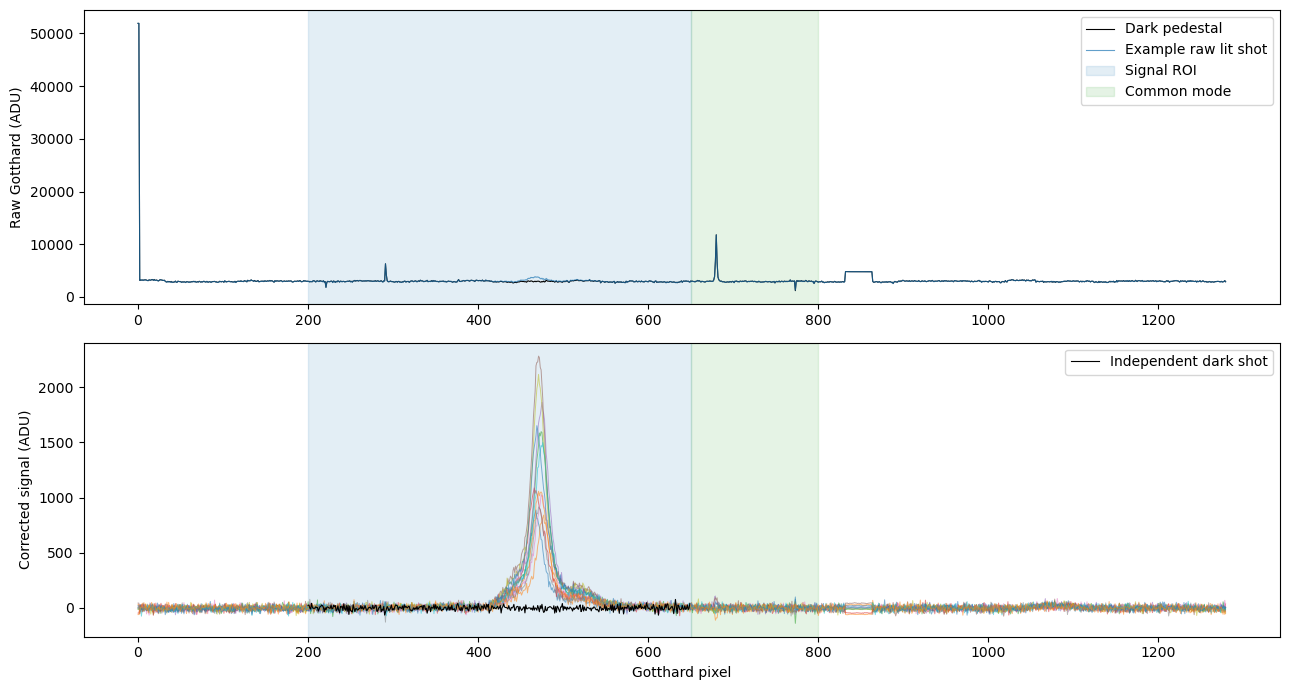

In [6]:
# A few lit shots, selected across the run; only keep a small preview.
rng = np.random.default_rng(SEED)
preview_rows = rows[np.linspace(0, len(rows)-1, min(12, len(rows)), dtype=int)]
preview = []
preview_gmd = []
with h5py.File(h5_path, 'r') as f:
    for r, frames in iter_vls(f, preview_rows):
        for j, row in enumerate(r):
            g = f['gmd'][row, slice(*BUNCH_RANGE)]
            a = frames[j, slice(*BUNCH_RANGE)]
            ok = np.flatnonzero(np.isfinite(g) & (g >= GMD_MIN) & np.all(np.isfinite(a), axis=1) & np.any(a != 0, axis=1))
            if ok.size:
                k = ok[np.argmax(g[ok])]
                preview.append(a[k]); preview_gmd.append(g[k])
assert preview, 'No lit preview shots; check GMD and the bunch range.'
preview = np.asarray(preview, dtype=float)
fig, ax = plt.subplots(2, 1, figsize=(13, 7))
ax[0].plot(background, color='k', lw=0.8, label='Dark pedestal')
ax[0].plot(preview[0], color='C0', lw=0.8, alpha=0.7, label='Example raw lit shot')
ax[0].axvspan(*VLS_ROI, color='C0', alpha=0.12, label='Signal ROI')
ax[0].axvspan(*CM_PIXELS, color='C2', alpha=0.12, label='Common mode')
ax[0].legend(); ax[0].set_ylabel('Raw Gotthard (ADU)')
full = preview-background
full -= np.median(full[:, cm], axis=1, keepdims=True)
for a in full:
    ax[1].plot(a, lw=0.7, alpha=0.55)
ax[1].plot(pixels, dark_corr[0], color='k', lw=0.8, label='Independent dark shot')
ax[1].axvspan(*VLS_ROI, color='C0', alpha=0.12)
ax[1].axvspan(*CM_PIXELS, color='C2', alpha=0.12)
ax[1].set_xlabel('Gotthard pixel'); ax[1].set_ylabel('Corrected signal (ADU)'); ax[1].legend()
fig.tight_layout(); plt.show()

## 4. Pair-scan detector (from the previous beamtime)
The highest-scoring eligible pair is tested for a valley between peaks. The old criterion is a relative valley drop of at least 1.5% **or** a drop of at least 0.75 times the noise. That is permissive; a pair is a candidate, not proof of distinct spikes. A 35% shot-relative height floor also means the nominal 5% second/first ratio is effectively redundant. The 3–17 pixel separation and 9-pixel smoothing need checking against the present spectrometer response.

In [7]:
def detect_double_peaks_pairscan(
    xcorr: np.ndarray,
    xsm: np.ndarray,
    noise: np.ndarray,
    *,
    proxy_pixel: Optional[np.ndarray] = None,
    min_distance_px: int = 3,
    max_distance_px: int = 17,
    min_prom_sigma: float = 2.5,
    min_height_sigma: float = 2.0,
    min_rel_peak_height: float = 0.35,
    min_width_px: float = 1.0,
    max_width_px: float = 40.0,
    min_second_ratio: float = 0.05,
    min_bridge_drop: float = 0.015,
    min_split_sigma: float = 0.75,
    max_peaks_to_score: int = 20,
    proxy_weight: float = 0.10,
) -> dict[str, np.ndarray]:
    """Detect shots with two resolved VLS peaks."""

    yall = np.asarray(xsm, dtype=np.float64)
    nshots, _ = yall.shape

    is_candidate = np.zeros(nshots, dtype=bool)
    peak1_px = np.full(nshots, -1, dtype=np.int16)
    peak2_px = np.full(nshots, -1, dtype=np.int16)
    second_ratio = np.full(nshots, np.nan, dtype=np.float64)
    valley_ratio = np.full(nshots, np.nan, dtype=np.float64)
    bridge_drop = np.full(nshots, np.nan, dtype=np.float64)
    split_sigma = np.full(nshots, np.nan, dtype=np.float64)
    sep = np.full(nshots, np.nan, dtype=np.float64)
    score = np.full(nshots, -np.inf, dtype=np.float64)
    n_peaks = np.zeros(nshots, dtype=np.int16)
    min_prom_snr = np.full(nshots, np.nan)
    min_rel_height = np.full(nshots, np.nan)

    for i in range(nshots):
        y = yall[i]
        sig = max(float(noise[i]), 1e-9)
        shot_max = np.nanmax(y)
        if not np.isfinite(shot_max) or shot_max <= 0:
            continue

        height_floor = max(min_height_sigma * sig, min_rel_peak_height * shot_max)
        peaks, props = find_peaks(
            y,
            distance=int(min_distance_px),
            prominence=float(min_prom_sigma) * sig,
            height=height_floor,
            width=(float(min_width_px), float(max_width_px)),
        )
        n_peaks[i] = len(peaks)
        if len(peaks) < 2:
            continue

        order = np.argsort(props["prominences"])[::-1][: int(max_peaks_to_score)]
        peaks = peaks[order]
        heights = props["peak_heights"][order]
        prominences = props["prominences"][order]
        best = None

        for ia in range(len(peaks)):
            for ib in range(ia + 1, len(peaks)):
                p1, p2 = int(peaks[ia]), int(peaks[ib])
                h1, h2 = float(heights[ia]), float(heights[ib])
                pr1, pr2 = float(prominences[ia]), float(prominences[ib])
                lo, hi = sorted((p1, p2))
                s = hi - lo
                if s < min_distance_px or s > max_distance_px:
                    continue
                weaker = min(h1, h2)
                stronger = max(h1, h2)
                if weaker <= 0 or stronger <= 0:
                    continue
                valley = float(np.min(y[lo : hi + 1]))
                sr = weaker / stronger
                vr = valley / weaker
                bd = max((weaker - valley) / weaker, 0.0)
                ss = max((weaker - valley) / sig, 0.0)
                proxy_bonus = 1.0
                if proxy_pixel is not None:
                    proxy_bonus += proxy_weight * float(lo <= proxy_pixel[i] <= hi)
                sc = (
                    np.sqrt(max(min(pr1, pr2) / sig, 1e-6))
                    * np.sqrt(max(s, 1))
                    * sr
                    * (0.05 + bd)
                    * (1.0 + 0.20 * ss)
                    * proxy_bonus
                )
                if best is None or sc > best[0]:
                    best = (sc, lo, hi, sr, vr, bd, ss, s, min(pr1, pr2)/sig, weaker/shot_max)

        if best is None:
            continue
        sc, lo, hi, sr, vr, bd, ss, s, pr, rel = best
        min_prom_snr[i] = pr
        min_rel_height[i] = rel
        peak1_px[i] = lo
        peak2_px[i] = hi
        second_ratio[i] = sr
        valley_ratio[i] = vr
        bridge_drop[i] = bd
        split_sigma[i] = ss
        sep[i] = s
        score[i] = sc
        is_candidate[i] = (sr >= min_second_ratio) and ((bd >= min_bridge_drop) or (ss >= min_split_sigma))

    return {
        "is_candidate": is_candidate,
        "peak1_px": peak1_px,
        "peak2_px": peak2_px,
        "second_ratio": second_ratio,
        "valley_ratio": valley_ratio,
        "bridge_drop": bridge_drop,
        "split_sigma": split_sigma,
        "sep": sep,
        "score": score,
        "n_peaks": n_peaks,
        "min_prom_snr": min_prom_snr,
        "min_rel_height": min_rel_height,
    }

In [8]:
# Basic regression test: the two clean shapes from test_static_xas_analysis.py.
x = np.arange(80)
single = 100*np.exp(-0.5*((x-35)/3)**2)
double = 100*np.exp(-0.5*((x-30)/2)**2) + 70*np.exp(-0.5*((x-40)/2)**2)
a, sm, sig = preprocess_shots_for_peakfinding(np.vstack([single, double]), noise_floor=0.1)
test = detect_double_peaks_pairscan(a, sm, sig, **STRICT)
assert test['is_candidate'].tolist() == [False, True], test
print('Clean Gaussian regression test passed.')

Clean Gaussian regression test passed.


## 5. Classify the shots
The denominator is all selected bunch slots with finite GMD >= GMD_MIN (not all acquisition slots). Missing VLS frames stay in that denominator. No VLS intensity percentile or electron/ion cut is applied.

- **Single:** one qualifying strict peak and no relaxed double candidate.
- **Double:** exactly two qualifying strict peaks and a passing strict pair.
- **Multi (3+):** three or more qualifying strict peaks; not necessarily three resolved physical spikes.
- **Weak / noisy:** signal fails the dark/SNR test, or no qualifying peak is found.
- **Borderline / ambiguous:** a relaxed pair only, two strict peaks but no accepted pair, or an ROI-edge maximum.
- **Missing VLS:** missing train/frame, nonfinite spectrum or all-zero frame.

Relaxed-only candidates are not added to the main double count. The legacy pair rate (any passing pair, even among 3+ peaks) is also printed separately. The old notebook's fixed intensity cut is not reproduced, so the rates are not directly identical. Classification is based on resolved spectral structure; closely spaced, weak or unresolved peaks may be missed.

In [9]:
# Compact shot-level metadata, not the spectra. Missing raw trains are retained.
b0, b1 = BUNCH_RANGE
nb = b1-b0
shape = (len(rows), nb)
labels = ['Missing VLS', 'Weak / noisy', 'Single', 'Double', 'Multi (3+)', 'Borderline / ambiguous']
# -1 = excluded by GMD; 0..5 correspond to the labels above.
classes = np.full(shape, -1, dtype=np.int8)
gmd_all = np.empty(shape, dtype=np.float32)
with h5py.File(h5_path, 'r') as f:
    for start in range(0, len(rows), 1000):
        r = rows[start:start+1000]
        gmd_all[start:start+len(r)] = f['gmd'][r, b0:b1]
eligible = np.isfinite(gmd_all) & (gmd_all >= GMD_MIN)
classes[eligible] = 0
assert eligible.any(), 'No eligible GMD shots.'

# Only diagnostic scalars retained; float32 keeps the memory cost modest.
metric_keys = ('second_ratio', 'bridge_drop', 'split_sigma', 'sep', 'score', 'min_prom_snr', 'min_rel_height')
metrics = {k: np.full(shape, np.nan, np.float32) for k in metric_keys}
peak1 = np.full(shape, -1, np.int16)
peak2 = np.full(shape, -1, np.int16)
n_peaks = np.full(shape, -1, np.int16)
strict_pair = np.zeros(shape, bool)
relaxed_pair = np.zeros(shape, bool)
peak_snr = np.full(shape, np.nan, np.float32)
edge = np.zeros(shape, bool)
received = np.zeros(len(rows), bool)

with h5py.File(h5_path, 'r') as f:
    for block_no, (r, frames) in enumerate(iter_vls(f, rows)):
        rr = np.searchsorted(rows, r)
        assert np.array_equal(rows[rr], r)
        received[rr] = True
        a = frames[:, b0:b1, :]
        ok = eligible[rr] & np.all(np.isfinite(a), axis=-1) & np.any(a != 0, axis=-1)
        it, ib = np.where(ok)
        if not len(it):
            continue
        loc = (rr[it], ib)
        corr = correct_vls(a[it, ib])
        xc, sm, sig = preprocess_shots_for_peakfinding(corr, noise_floor)
        max_y = sm.max(axis=1)
        snr = max_y/sig
        peak_snr[loc] = snr
        classes[loc] = 1
        signal = (max_y > signal_threshold) & (snr >= MIN_SIGNAL_SIGMA)
        if not signal.any():
            continue
        loc = (loc[0][signal], loc[1][signal])
        xc, sm, sig, corr = xc[signal], sm[signal], sig[signal], corr[signal]
        pos = np.maximum(corr, 0)
        com = np.divide(pos @ np.arange(len(pixels)), pos.sum(axis=1),
                        out=np.zeros(len(pos)), where=pos.sum(axis=1)>0)
        proxy = np.rint(com) if COM_BONUS else None
        ds = detect_double_peaks_pairscan(xc, sm, sig, proxy_pixel=proxy, **STRICT)
        dr = detect_double_peaks_pairscan(xc, sm, sig, proxy_pixel=proxy, **RELAXED)
        ns = ds['n_peaks']
        strict_pair[loc] = ds['is_candidate']
        relaxed_pair[loc] = dr['is_candidate']
        n_peaks[loc] = ns
        # Prefer strict pair diagnostics when accepted; otherwise show relaxed pair if available.
        use_relaxed = ~ds['is_candidate'] & (dr['peak1_px'] >= 0)
        for key in metric_keys:
            metrics[key][loc] = np.where(use_relaxed, dr[key], ds[key])
        peak1[loc] = np.where(use_relaxed, dr['peak1_px'], ds['peak1_px'])
        peak2[loc] = np.where(use_relaxed, dr['peak2_px'], ds['peak2_px'])
        c = np.full(len(ns), 1, np.int8)
        c[(ns == 1) & ~dr['is_candidate']] = 2
        c[(ns == 2) & ds['is_candidate']] = 3
        c[ns >= 3] = 4
        c[((ns <= 1) & dr['is_candidate']) | ((ns == 2) & ~ds['is_candidate'])] = 5
        max_px = sm.argmax(axis=1)
        near_edge = (max_px < SG_WINDOW//2) | (max_px >= len(pixels)-SG_WINDOW//2)
        # Also flag selected pairs too close to the ROI boundary.
        p1, p2 = peak1[loc], peak2[loc]
        near_edge |= (p1 >= 0) & ((p1 < SG_WINDOW//2) | (p2 >= len(pixels)-SG_WINDOW//2))
        edge[loc] = near_edge
        c[near_edge] = 5
        classes[loc] = c
        if block_no % 100 == 0:
            print(f'Processed {received.sum():,} / {len(rows):,} trains', flush=True)

print(f'VLS trains received: {received.sum():,} / {len(rows):,}')
assert np.count_nonzero(classes >= 0) == np.count_nonzero(eligible)

Processed 32 / 1,184 trains
VLS trains received: 1,184 / 1,184


## 6. Counts and fractions
Report the full eligible population, plus the single/double ratio among only those two classes. The latter is conditional and should never be quoted as a fraction of all shots. The relaxed rate is a sensitivity diagnostic, not a corrected physical double-spike rate.

,class,shots,% of GMD-eligible shots
0,Missing VLS,0,0.00
1,Weak / noisy,27111,23.90
2,Single,85758,75.61
3,Double,2,0.00
4,Multi (3+),2,0.00
5,Borderline / ambiguous,547,0.48


Selected bunch slots: 116,032
Excluded by GMD: 2,612 (2.25%)
Eligible shots: 113,420
Double / (single + double): 0.00%
Any strict pair / eligible:  0.00%
Any relaxed pair / eligible: 0.36%
ROI-edge ambiguous: 0


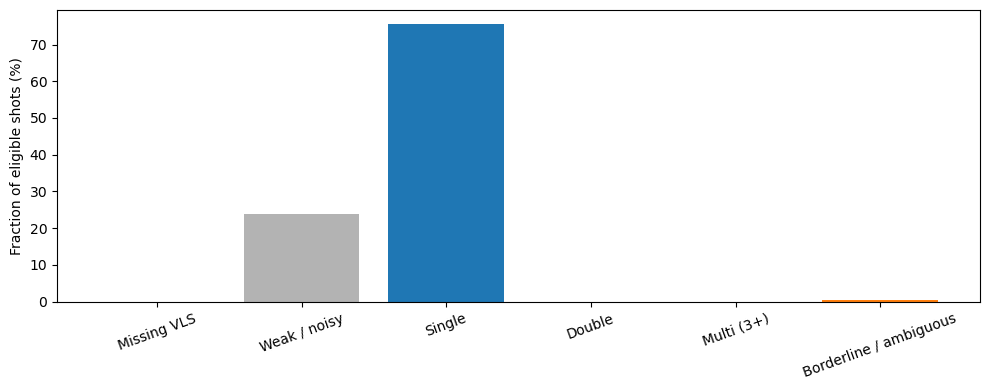

In [10]:
counts = np.bincount(classes[eligible], minlength=len(labels))
total = int(counts.sum())
summary = pd.DataFrame({'class': labels, 'shots': counts, '% of GMD-eligible shots': 100*counts/total})
display(summary.round(2))
print(f'Selected bunch slots: {classes.size:,}')
print(f'Excluded by GMD: {np.count_nonzero(~eligible):,} ({np.count_nonzero(~eligible)/classes.size:.2%})')
print(f'Eligible shots: {total:,}')
if counts[2] + counts[3]:
    print(f'Double / (single + double): {counts[3]/(counts[2]+counts[3]):.2%}')
print(f'Any strict pair / eligible:  {strict_pair.sum()/total:.2%}')
print(f'Any relaxed pair / eligible: {relaxed_pair.sum()/total:.2%}')
print(f'ROI-edge ambiguous: {edge.sum():,}')
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(labels, 100*counts/total, color=['0.6','0.7','C0','C3','C4','C1'])
ax.set_ylabel('Fraction of eligible shots (%)'); ax.tick_params(axis='x', rotation=20)
fig.tight_layout(); plt.show()

## 7. Examples — random doubles, near-cut doubles, relaxed-only candidates, singles and weak shots
The near-cut set ranks accepted doubles by the smallest relative margin to the height, prominence, separation or valley cut. Separation at either inclusive boundary has zero margin. The relaxed-only set shows candidates missed by the strict search; their selected pair may differ. This is a diagnostic, not a probability score. The plots reread only the selected frames, so the full spectra are never held in memory.

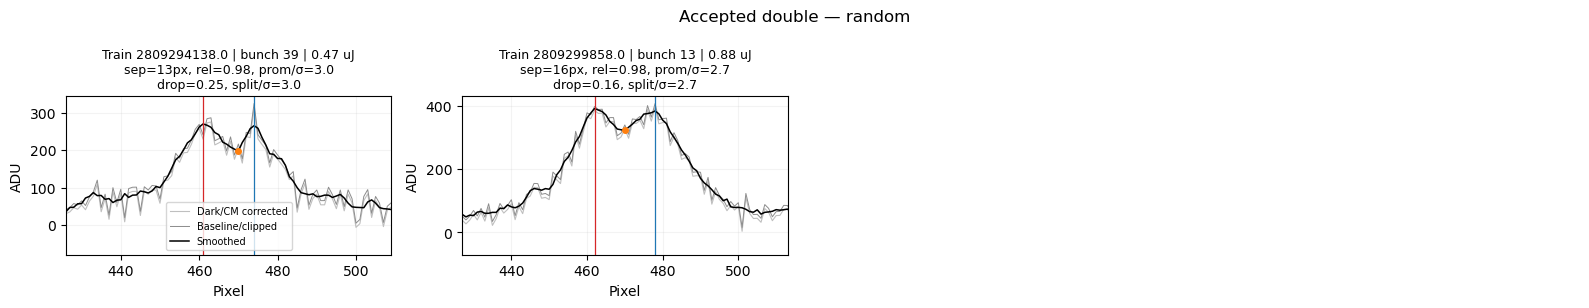

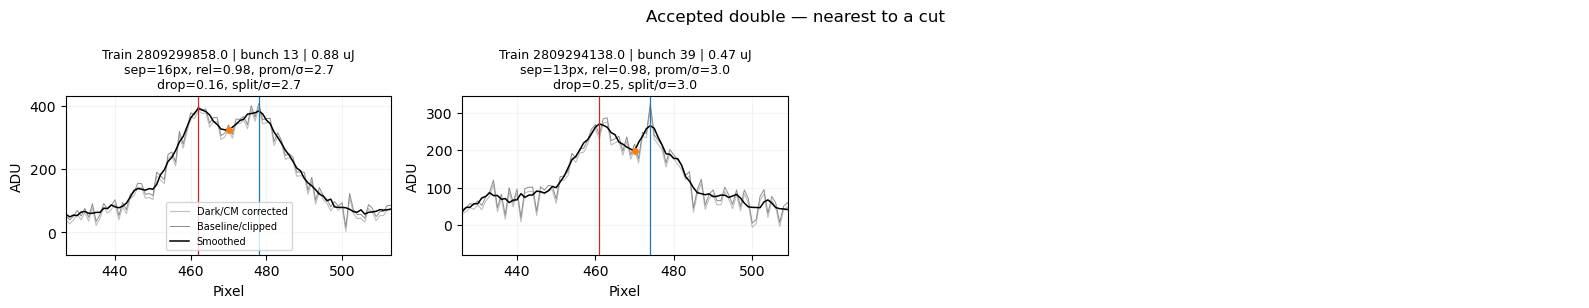

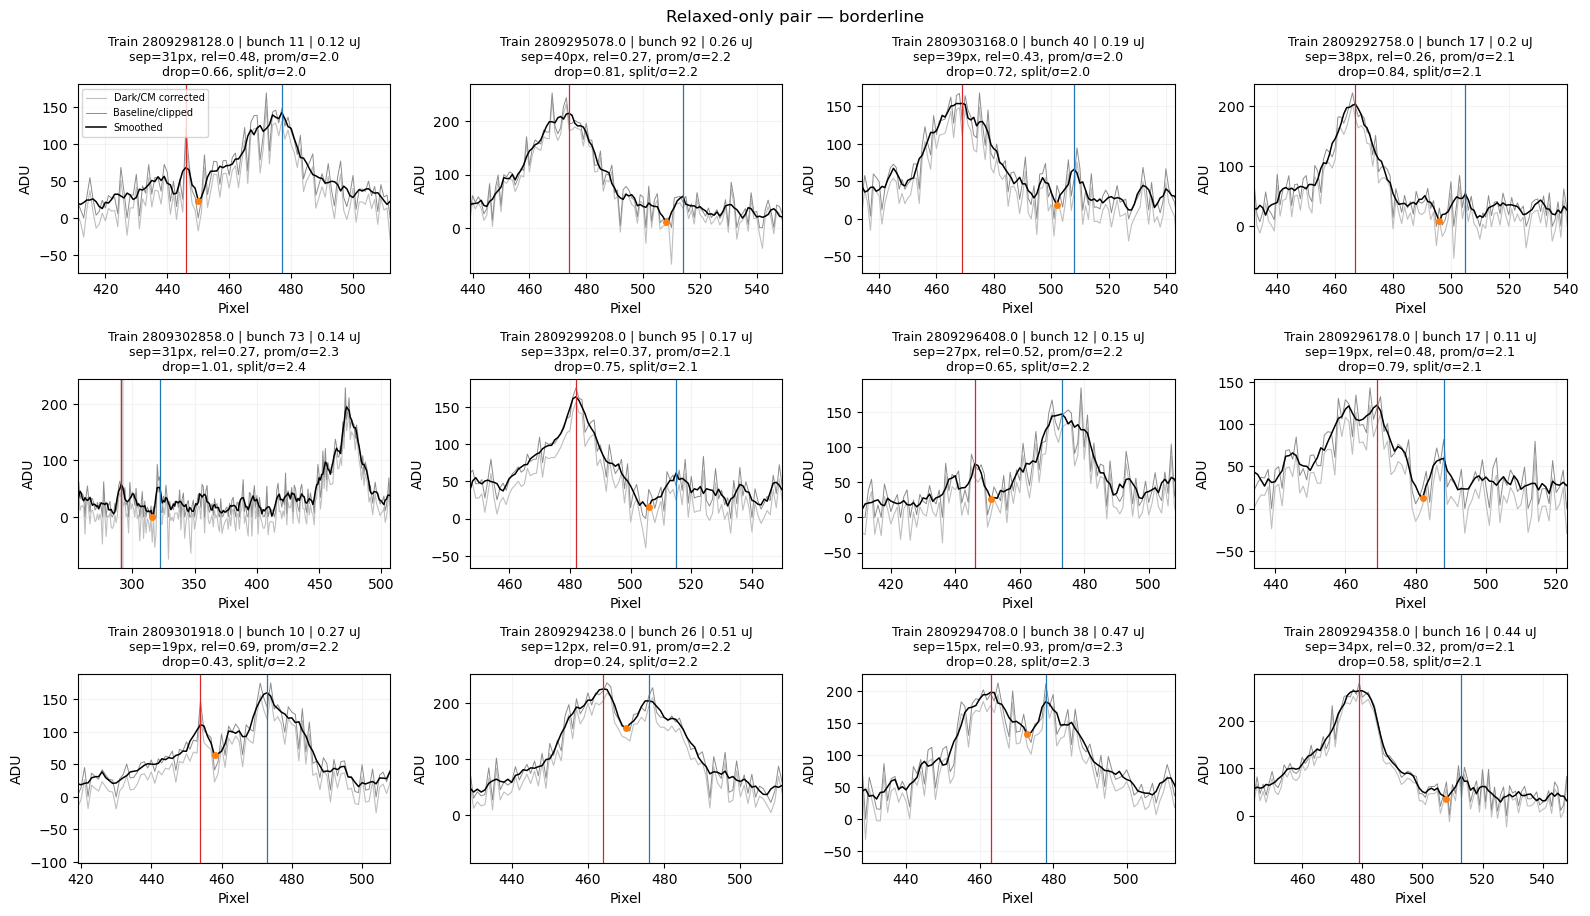

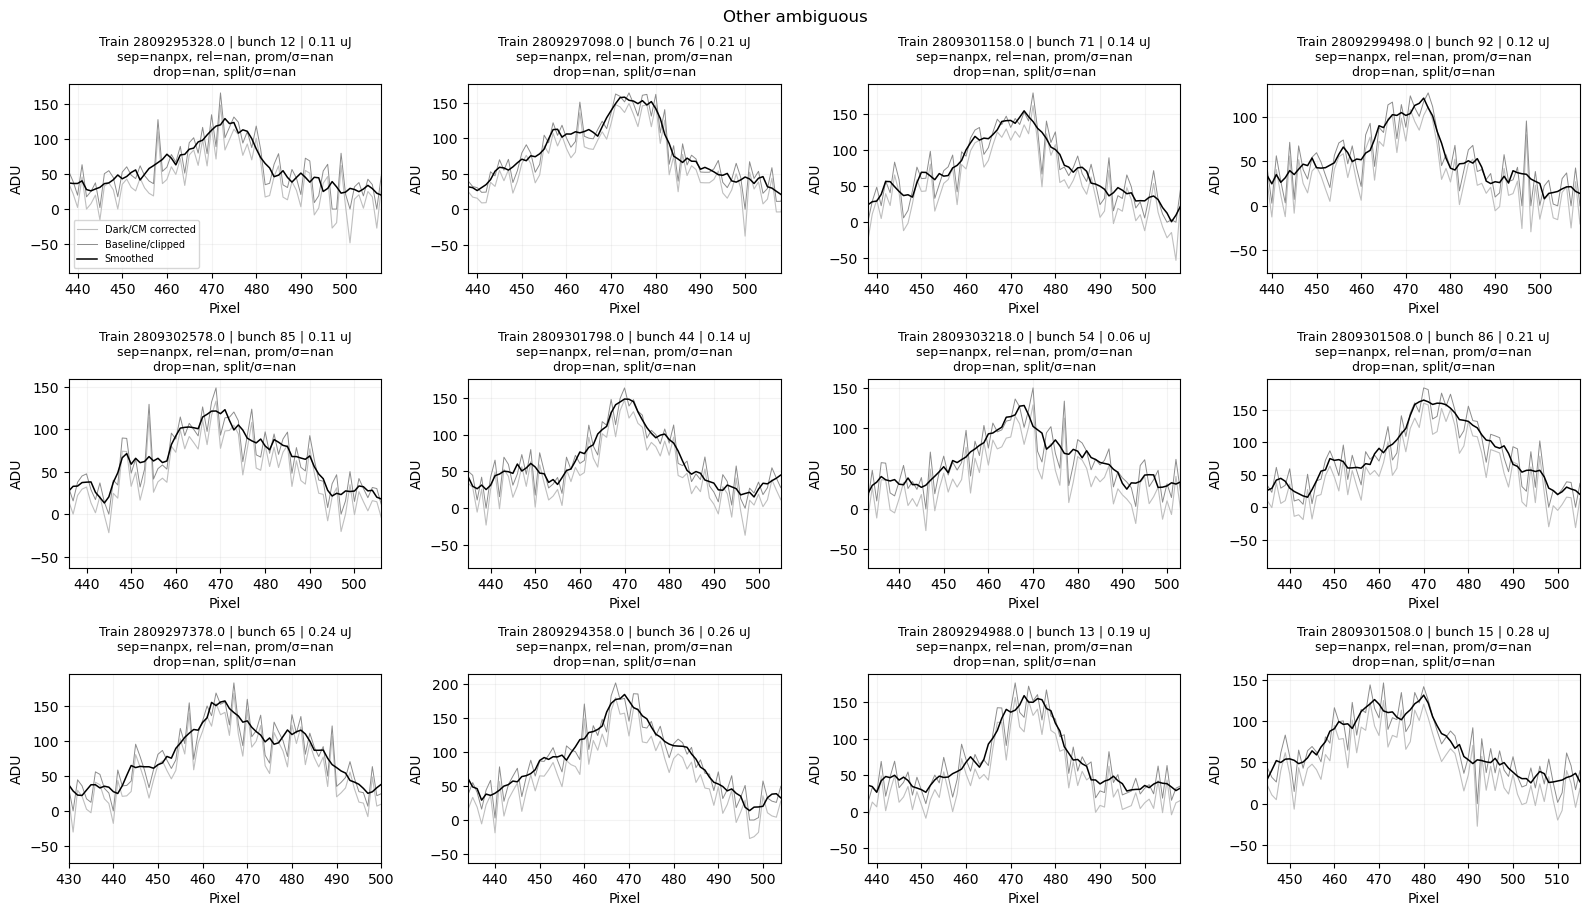

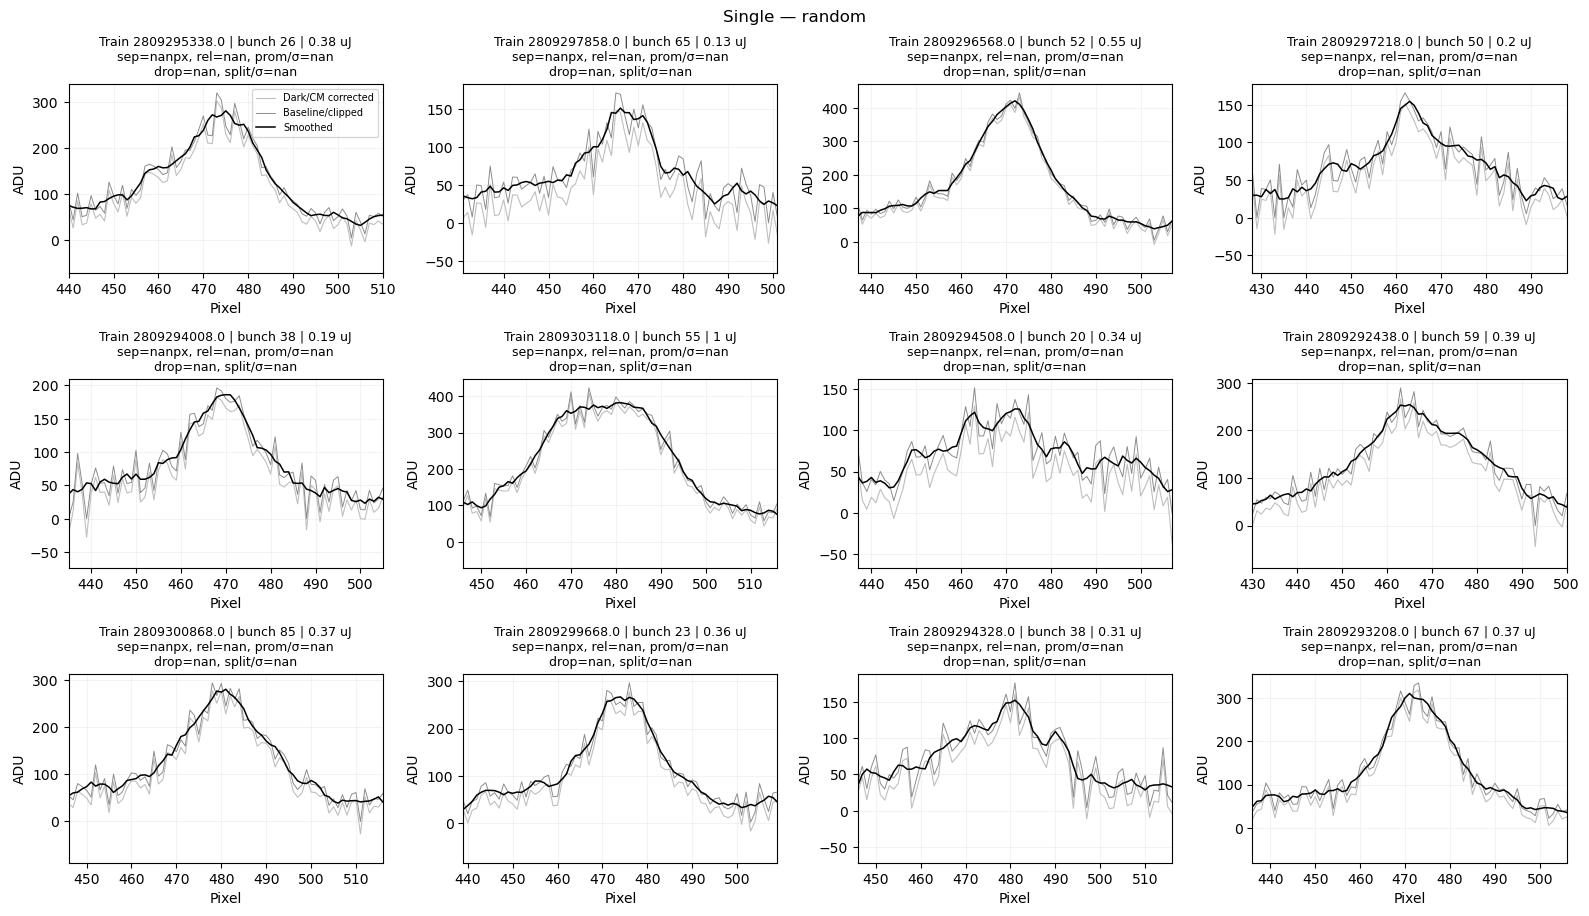

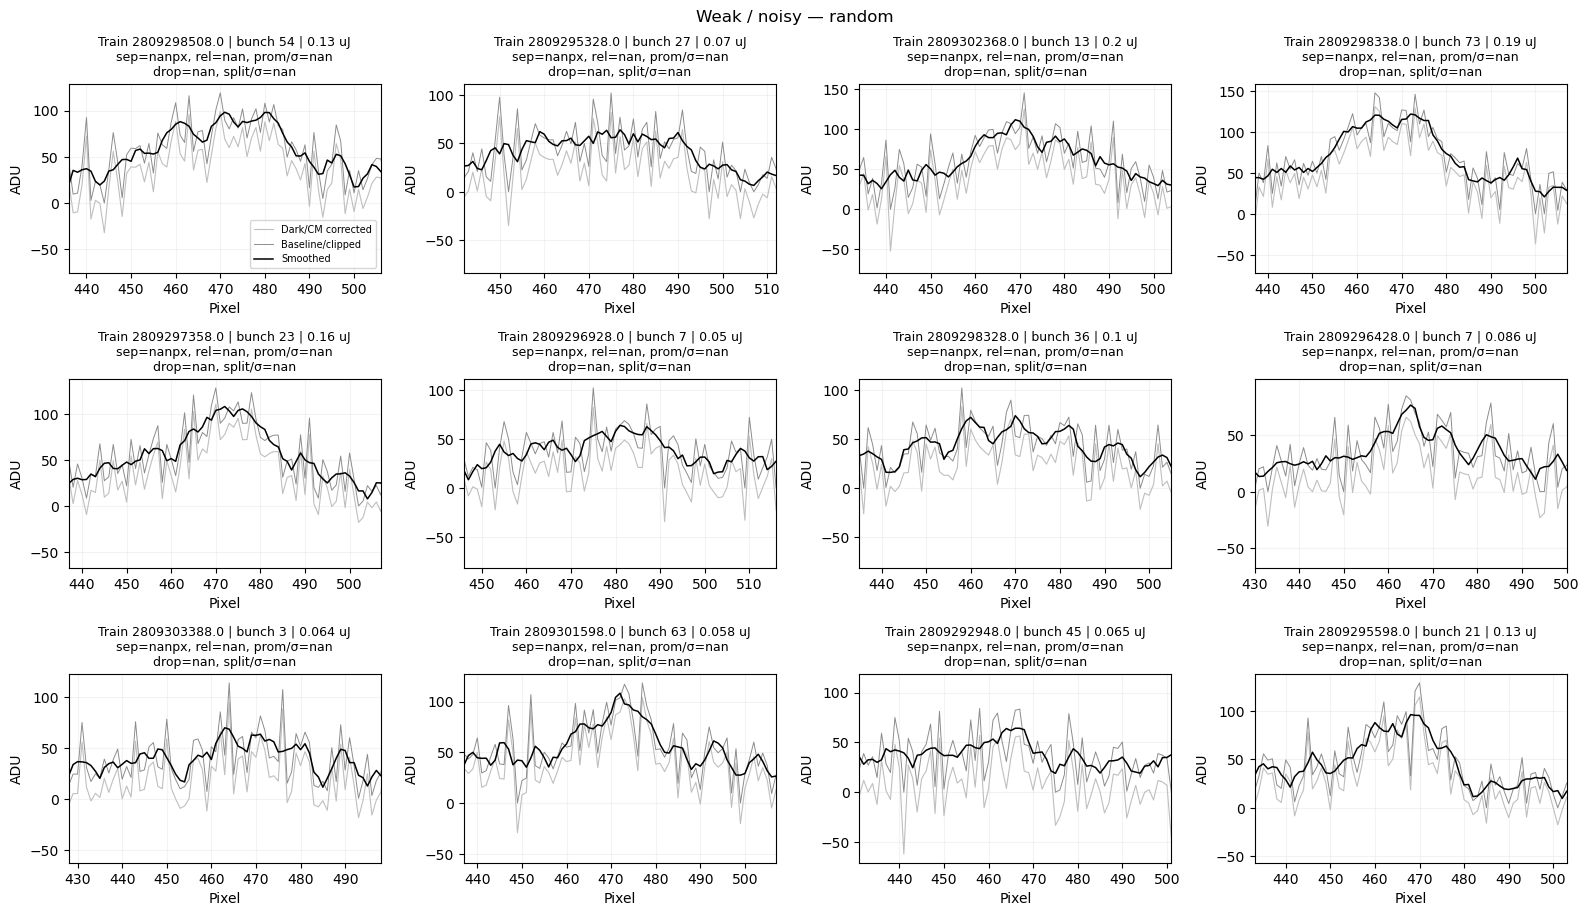

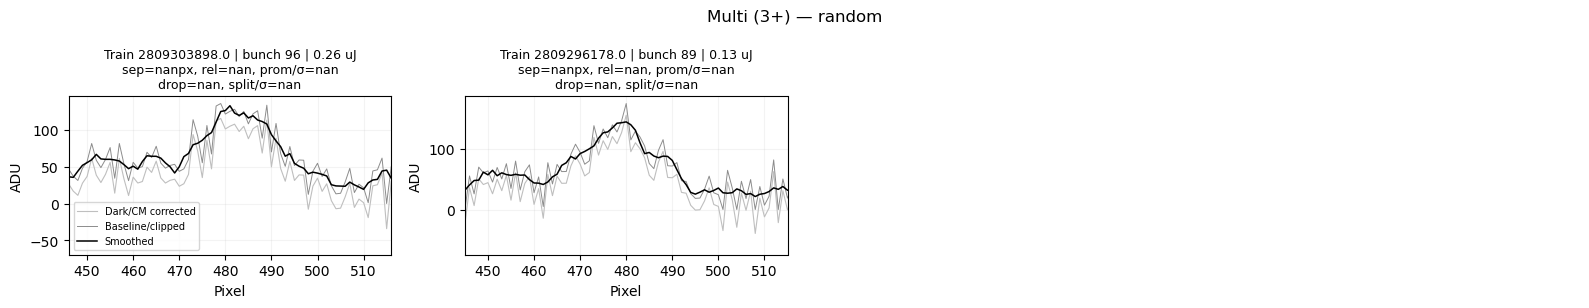

In [11]:
# Choose examples using the compact arrays above.
rng = np.random.default_rng(SEED)
flat_class = classes.ravel()
flat = {k: v.ravel() for k, v in metrics.items()}
double_idx = np.flatnonzero(flat_class == 3)
# OR valley criterion: the larger margin governs acceptance.
valley_margin = np.maximum(flat['bridge_drop']/STRICT['min_bridge_drop']-1,
                           flat['split_sigma']/STRICT['min_split_sigma']-1)
margin = np.minimum.reduce([flat['min_rel_height']/STRICT['min_rel_peak_height']-1,
                            flat['min_prom_snr']/STRICT['min_prom_sigma']-1,
                            (flat['sep']-STRICT['min_distance_px'])/STRICT['min_distance_px'],
                            (STRICT['max_distance_px']-flat['sep'])/STRICT['max_distance_px'],
                            valley_margin])

def random_examples(idx):
    return rng.choice(idx, min(N_EXAMPLES, len(idx)), replace=False)

groups = {
    'Accepted double — random': random_examples(double_idx),
    'Accepted double — nearest to a cut': double_idx[np.argsort(margin[double_idx])[:N_EXAMPLES]],
    'Relaxed-only pair — borderline': random_examples(np.flatnonzero((flat_class == 5) & relaxed_pair.ravel() & ~strict_pair.ravel())),
    'Other ambiguous': random_examples(np.flatnonzero((flat_class == 5) & ~(relaxed_pair.ravel() & ~strict_pair.ravel()))),
    'Single — random': random_examples(np.flatnonzero(flat_class == 2)),
    'Weak / noisy — random': random_examples(np.flatnonzero(flat_class == 1)),
    'Multi (3+) — random': random_examples(np.flatnonzero(flat_class == 4)),
}
example_ids = np.unique(np.concatenate(list(groups.values())))
example_rows = rows[example_ids//nb]
wanted_rows = np.unique(example_rows)
example_spectra = {}
if len(wanted_rows):
    with h5py.File(h5_path, 'r') as f:
        for r, frames in iter_vls(f, wanted_rows):
            for j, row in enumerate(r):
                for idx in example_ids[example_rows == row]:
                    example_spectra[int(idx)] = frames[j, b0+idx%nb].copy()

for title, ids in groups.items():
    ids = [int(i) for i in ids if int(i) in example_spectra]
    if not ids:
        print(f'{title}: no examples'); continue
    a = correct_vls(np.stack([example_spectra[i] for i in ids]))
    xc, sm, sig = preprocess_shots_for_peakfinding(a, noise_floor)
    ncols = 4
    fig, axes = plt.subplots(int(np.ceil(len(ids)/ncols)), ncols,
                             figsize=(16, 3.1*np.ceil(len(ids)/ncols)), squeeze=False)
    for j, (ax, idx) in enumerate(zip(axes.ravel(), ids)):
        ax.plot(pixels, a[j], color='0.75', lw=0.8, label='Dark/CM corrected')
        ax.plot(pixels, xc[j], color='0.55', lw=0.7, label='Baseline/clipped')
        ax.plot(pixels, sm[j], color='k', lw=1.1, label='Smoothed')
        p1, p2 = peak1.ravel()[idx], peak2.ravel()[idx]
        if p1 >= 0 and p2 >= 0:
            ax.axvline(pixels[p1], color='C3', lw=0.9)
            ax.axvline(pixels[p2], color='C0', lw=0.9)
            v = p1 + np.argmin(sm[j, p1:p2+1])
            ax.plot(pixels[v], sm[j, v], 'o', color='C1', ms=4)
        for p in np.intersect1d(pixels, bad):
            ax.axvspan(p-0.5, p+0.5, color='0.7', alpha=0.25)
        # Zoom on peak(s), with full ROI available in the raw preview.
        centre = int(sm[j].argmax())
        lo = max(0, min(centre, p1 if p1 >= 0 else centre)-35)
        hi = min(len(pixels)-1, max(centre, p2 if p2 >= 0 else centre)+35)
        ax.set_xlim(pixels[lo], pixels[hi])
        row = rows[idx//nb]; bunch = b0+idx%nb
        ax.set_title(f'Train {tid[row]} | bunch {bunch} | {gmd_all.ravel()[idx]:.2g} uJ\n'
                     f'sep={flat["sep"][idx]:.0f}px, rel={flat["min_rel_height"][idx]:.2f}, '
                     f'prom/σ={flat["min_prom_snr"][idx]:.1f}\n'
                     f'drop={flat["bridge_drop"][idx]:.2f}, split/σ={flat["split_sigma"][idx]:.1f}', fontsize=9)
        ax.set_xlabel('Pixel'); ax.set_ylabel('ADU'); ax.grid(alpha=0.15)
    for ax in axes.ravel()[len(ids):]:
        ax.axis('off')
    axes.ravel()[0].legend(fontsize=7, loc='best')
    fig.suptitle(title); fig.tight_layout(); plt.show()

## 8. Check for bunch-position and GMD bias
A high double fraction at a particular bunch slot or pulse energy may indicate detector response or changes in lasing. Check this before using the selection in a delay scan. The GMD bins below are equal-count diagnostic bins; they do not alter the classification.

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7))
colors = ['0.6','0.7','C0','C3','C4','C1']
per_bunch = eligible.sum(axis=0)
for j, name in enumerate(labels):
    frac = np.divide((classes == j).sum(axis=0), per_bunch,
                     out=np.full(nb, np.nan), where=per_bunch>0)
    ax[0].plot(np.arange(b0, b1), 100*frac, label=name, color=colors[j])
ax[0].set_xlabel('Bunch slot'); ax[0].set_ylabel('Fraction (%)'); ax[0].legend(ncol=3, fontsize=8)

g = gmd_all[eligible]; c = classes[eligible]
g_edges = np.unique(np.quantile(g, np.linspace(0, 1, 11)))
if len(g_edges) >= 2:
    gb = np.clip(np.searchsorted(g_edges, g, side='right')-1, 0, len(g_edges)-2)
    den = np.bincount(gb, minlength=len(g_edges)-1)
    centres = np.divide(np.bincount(gb, weights=g, minlength=len(den)), den,
                        out=np.full(len(den), np.nan), where=den>0)
    for j, name in enumerate(labels):
        num = np.bincount(gb[c==j], minlength=len(den))
        ax[1].plot(centres, 100*np.divide(num, den, out=np.full(len(den), np.nan), where=den>0), 'o-', color=colors[j], label=name)
    ax[1].set_xlabel('Mean GMD in bin (uJ)'); ax[1].set_ylabel('Fraction (%)')
else:
    ax[1].text(0.5, 0.5, 'GMD constant — no bins', ha='center', transform=ax[1].transAxes)
fig.tight_layout(); plt.show()

## 9. Optional shot table
Train ID and bunch slot allow the classification to be joined to the delay/electron/ion analysis later. The CSV is disabled by default. No original data files are modified.

In [ ]:
if SAVE_CSV:
    it, ib = np.where(eligible)
    loc = (it, ib)
    table = pd.DataFrame({'train_id': tid[rows[it]], 'bunch': b0+ib,
                          'gmd_uJ': gmd_all[loc], 'class': np.asarray(labels)[classes[loc]],
                          'n_strict_peaks': n_peaks[loc], 'strict_pair': strict_pair[loc],
                          'relaxed_pair': relaxed_pair[loc], 'peak_snr': peak_snr[loc],
                          'peak1_px': np.where(peak1[loc]>=0, peak1[loc]+pixels[0], np.nan),
                          'peak2_px': np.where(peak2[loc]>=0, peak2[loc]+pixels[0], np.nan),
                          **{k: v[loc] for k,v in metrics.items()}})
    out = Path.cwd() / f'{h5_path.stem}_gotthard_spikes.csv'
    table.to_csv(out, index=False)
    print(out)

## Before using the fraction as a scientific result
Inspect random and near-cut samples, dark frames and the ROI. Repeat with e.g. SG_WINDOW=5 or 7 and 11, and vary the relative height and maximum separation. A change in the number of detected peaks with smoothing is expected when close to the instrument resolution. The original OR valley criterion may accept shallow shoulders; test a stronger valley criterion before applying a hard cut to the science data. The relaxed search is not guaranteed to be a superset because the highest-scoring pair can change. No saturation threshold is assumed here: inspect raw values/flat tops and detector limits, then add a measured saturation cut if necessary. Verify the dark slot and GMD floor for each run. Do not claim temporal pulse multiplicity from spectral intensity alone. If using the labels for delay traces, check class fraction and counts versus calibrated delay and compare independent runs before combining.